# Gradient Descent

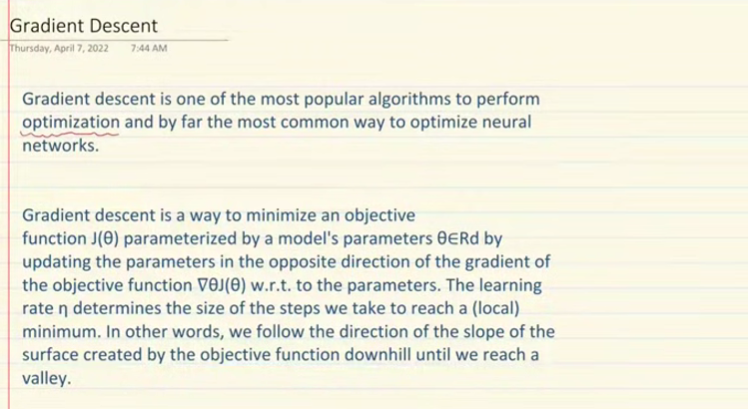

- In NN Gradient descent is used in the Update step of the Backpropagation algorithm to update the weights and bias of the NN in order to minimize the loss function.

## Types of Gradient Descent:

1. Batch Gradient Descent: In this type of gradient descent, the entire training dataset is used to compute the gradient of the loss function with respect to the parameters (weights and bias) and update them in one go. This can be computationally expensive for large datasets.

2. Stochastic Gradient Descent (SGD): In this type of gradient descent, a single training example is used to compute the gradient and update the parameters. This can be faster than batch gradient descent, but it can also be noisy and may not converge to the minimum loss.

3. Mini-batch Gradient Descent: In this type of gradient descent, a small batch of training examples is used to compute the gradient and update the parameters. This strikes a balance between the computational efficiency of SGD and the stability of batch gradient descent.

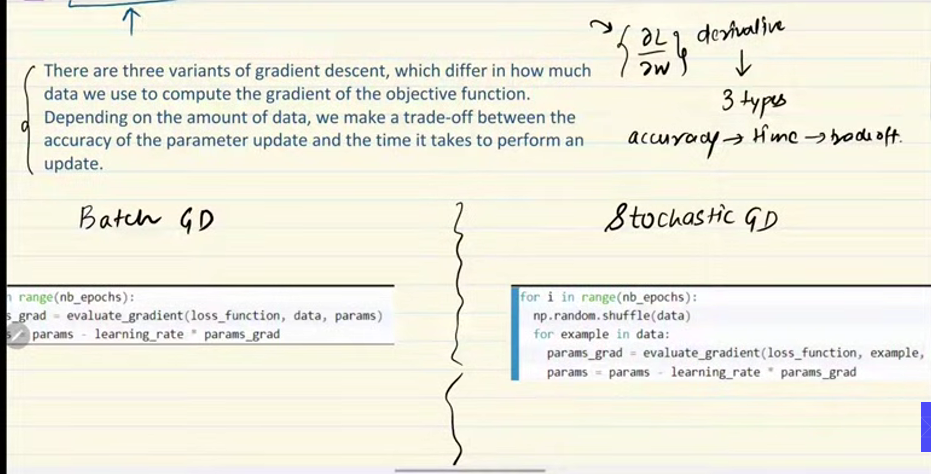

## 1. Batch Gradient Descent

- For a dataset with 50 points, we will use all 50 points to compute the gradient and update the parameters for each iteration.

- So, the number of times the parameters will be updated is same as number of epochs (number of iterations) and not number of training examples (50 in this case)

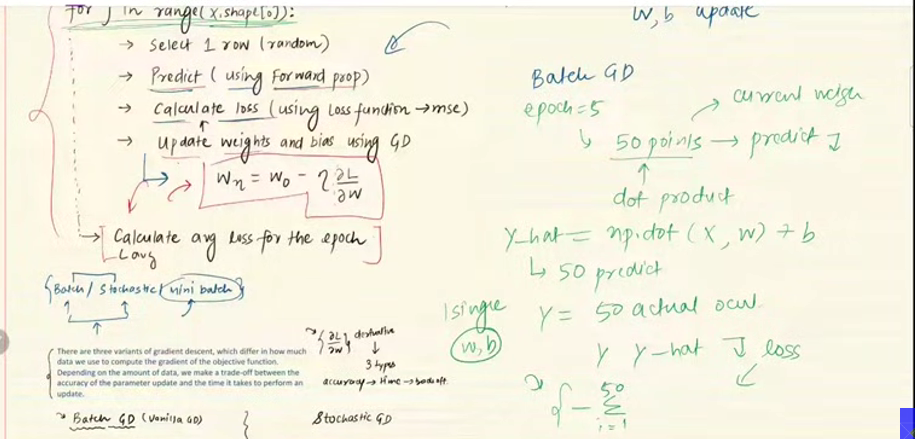

- Steps:
1. Initialize the parameters (weights and bias) randomly.
2. Compute the predicted output using the current parameters for all 50 points.
3. Compute the cost using the predicted output and the actual output for all 50 points.
4. Compute the gradients of the cost with respect to the parameters
    $$
    J(w, b) = \frac{1}{m} \sum_{i=1}^{m} L(\hat{y}^{(i)})
    $$

    - where $m$ is the number of training examples.
5. Update the parameters using the gradients and learning rate
    $$w = w - \alpha \frac{\partial J}{\partial w}$$
    $$b = b - \alpha \frac{\partial J}{\partial b}$$

## 2. Stochastic Gradient Descent (SGD)

- For a dataset with 50 points, we will use one point at a time to compute the gradient and update the parameters for each iteration.

- It is the same as we were doing till now in the Backpropagation module

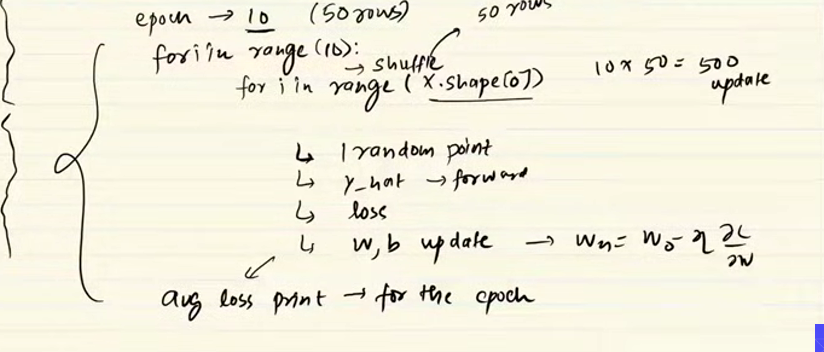

### Which is faster, BGD or SGD? (Given the same number of epochs)

- Batch Gradient Descent is faster than Stochastic Gradient Descent

- For a dataset with 50 points and $n$ epochs, Batch Gradient Descent will update the parameters $n$ times (once per epoch), while Stochastic Gradient Descent will update the parameters $50n$ times (once per training example per epoch).

- You can see the comparison of time taken by both the algorithms in the attached [notebook](./Batch_vs_stochastic_GD.ipynb)

### Which is faster to converge, BGD or SGD? (Given the same number of epochs)

- Stochastic Gradient Descent is faster to converge than Batch Gradient Descent because it takes more frequent updates to the parameters

- So for the same convergence, SGD will take less time than BGD, but it may not always converge to the minimum loss due to its noisy nature.


### Why in SGD the decrease in cost function is noisy and in BGD it is smooth?

- SGD:
    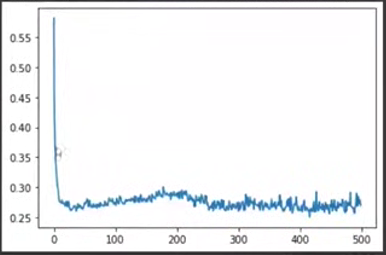

- BGD:
    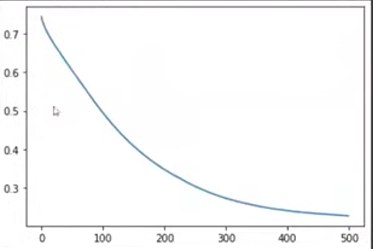

- It is because in SGD, we are updating the parameters for each training example, which can lead to fluctuations in the cost function as it may not always move towards the minimum loss. In contrast, BGD updates the parameters after computing the average gradient over the entire dataset, resulting in a smoother decrease in the cost function.

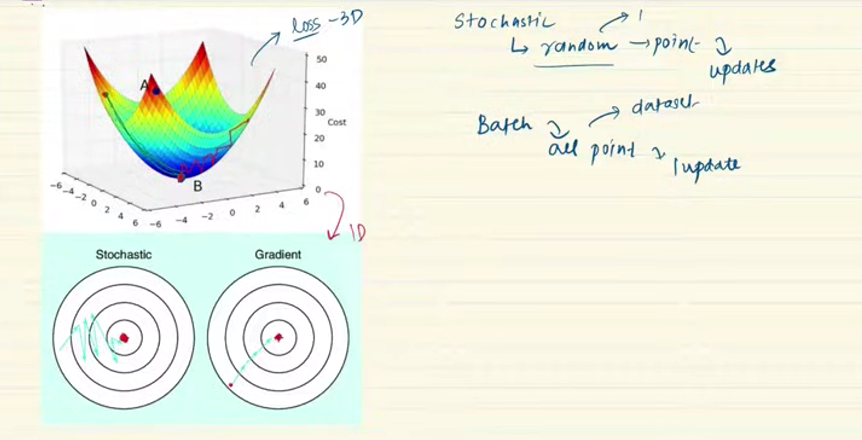

### Is this noisy nature of SGD useful?

- **Advantages of SGD's noise:**
    - **Escaping local minima:** The noise in SGD can help the algorithm escape from local minima (For a non-convex function) and potentially find a better global minimum.
    - **Memory efficiency:** SGD requires less memory as it processes one sample at a time, making it suitable for large datasets.

- **Disadvantages of SGD's noise:**
    - **Convergence issues:** The noise can cause the cost function to fluctuate, <span style="color: red;">making it converge at approximately the minimum loss rather than exactly at the minimum loss.</span>

### Vectorization 

- In BGD, we can compute the gradients for all training examples at once using matrix operations, which can be more efficient than computing the gradients for each training example individually in SGD. This is known as vectorization and can significantly speed up the training process for large datasets.

- Vectorization is a smart and efficient replacement of loop that has to be used in BGD

- But the downside of vectorization is that it can consume a lot of memory, especially for large datasets, which can lead to out-of-memory errors. In contrast, SGD processes one sample at a time, which can be more memory efficient.

## 3. Mini-batch Gradient Descent

- It is in between BGD and SGD
- In keras we can set the batch size to a value between 1 and the total number of training examples to use mini-batch gradient descent.

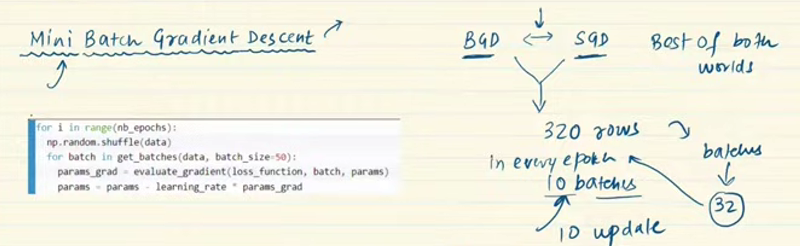

- The loss curve will be less noisy than SGD but more noisy than BGD

- Here vectors are computed for a batch of training examples, while still being more memory efficient than BGD.

# INTERVIEW QUESTIONS

### 1. Why batch_size is provided in multiple of 2 (like 32, 64, 128, etc.) 

- It is provided for the effective use of RAM and GPU memory. 

### 2. What if batch_size doesn't perfectly divide the number of training examples?

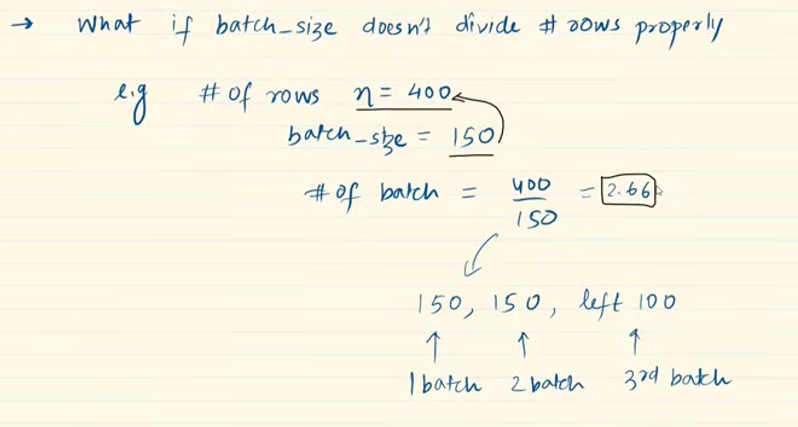  

- If the batch size does not perfectly divide the number of training examples, the last batch will contain the remaining training examples. For example, if we have 100 training examples and a batch size of 32, we will have 3 batches of 32 examples and 1 batch of 4 examples. The last batch will still be used to update the parameters